# ENCH 470 Fall 2021 Assignment 18: Introduction to RDKit

In [1]:
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import rdFingerprintGenerator
from rdkit import RDConfig
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem.Draw import IPythonConsole
from rdkit import DataStructs
from rdkit.Chem import Draw

import pubchempy

**<font color=red> Problem: </font>** The SMILES string for hexane is 'CCCCCC' and the SMILES string for cyclohexane is 'C1CCCCC1'. Write a loop to create two lists of SMILES strings, one for methane through decane, and one for cyclopropane through cyclodecane.

In [2]:
SMILE_alkanes = ['C'*i for i in range(1,11)]
print("SMILE strings for methane through decane:\n", SMILE_alkanes)

SMILE_cycloalkanes = ['C1{0}C1'.format('C'*i) for i in range(1,9)]
print("\nSMILE strings for cyclopropane through cyclodecane:\n", SMILE_cycloalkanes)

SMILE strings for methane through decane:
 ['C', 'CC', 'CCC', 'CCCC', 'CCCCC', 'CCCCCC', 'CCCCCCC', 'CCCCCCCC', 'CCCCCCCCC', 'CCCCCCCCCC']

SMILE strings for cyclopropane through cyclodecane:
 ['C1CC1', 'C1CCC1', 'C1CCCC1', 'C1CCCCC1', 'C1CCCCCC1', 'C1CCCCCCC1', 'C1CCCCCCCC1', 'C1CCCCCCCCC1']


**<font color=red> Problem: </font>** Convert your lists of alkanes into lists of RDKit molecule objects, and then display a grid for each of these.

In [3]:
#List of RDKit molecule objects
mol_alkanes = [Chem.MolFromSmiles(i) for i in SMILE_alkanes]
mol_arenes = [Chem.MolFromSmiles(i) for i in SMILE_cycloalkanes]


#Created this, to get names of molecules as caption
#Need to import pubchempy for this to run
alkaneNames = []
for smiles in SMILE_alkanes:
    PubChem_CID = pubchempy.get_compounds(smiles, namespace='smiles')
    match = PubChem_CID[0]
    alkaneNames.append(match.iupac_name)
print(alkaneNames)

cycloalkanesNames = []
for smiles in SMILE_cycloalkanes:
    PubChem_CID = pubchempy.get_compounds(smiles, namespace='smiles')
    match = PubChem_CID[0]
    cycloalkanesNames.append(match.iupac_name)
print(cycloalkanesNames)

['methane', 'ethane', 'propane', 'butane', 'pentane', 'hexane', 'heptane', 'octane', 'nonane', 'decane']
['cyclopropane', 'cyclobutane', 'cyclopentane', 'cyclohexane', 'cycloheptane', 'cyclooctane', 'cyclononane', 'cyclodecane']


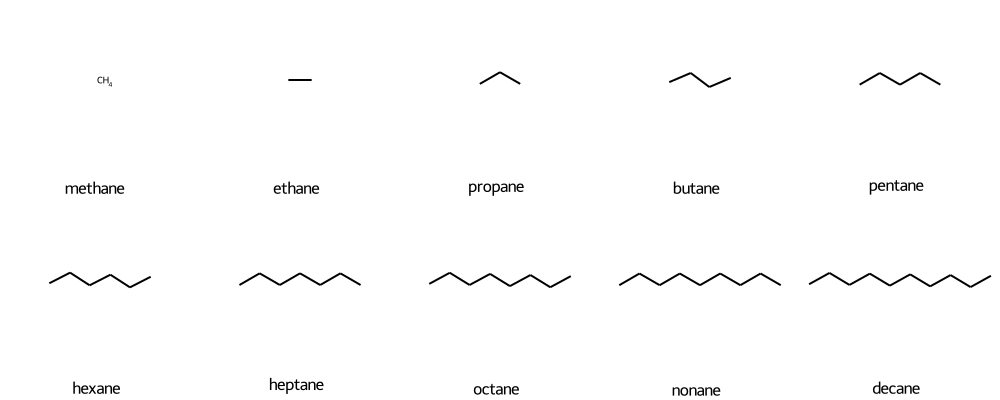

In [4]:
Draw.MolsToGridImage(mol_alkanes, molsPerRow=5, useSVG=True, legends=alkaneNames)

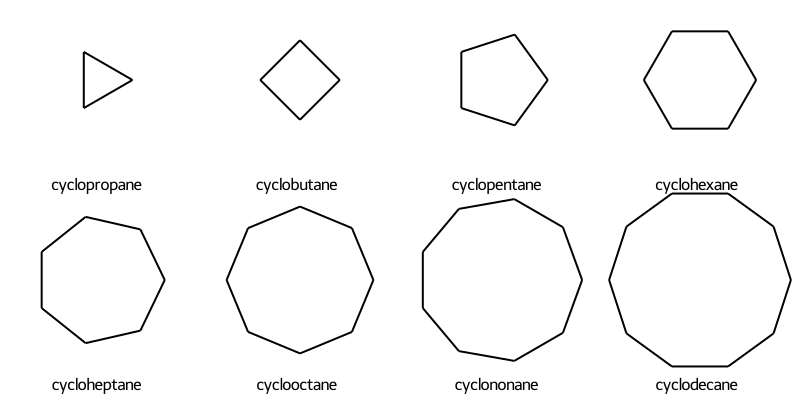

In [5]:
Draw.MolsToGridImage(mol_arenes, molsPerRow=4,useSVG=True, legends=cycloalkanesNames)

**<font color=red> Problem: </font>** Create a molecule object for ibuprofen and visualize it. 

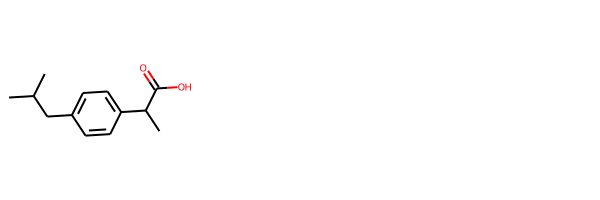

In [6]:
ibuprofen_mol  = Chem.MolFromSmiles('CC(C)CC1=CC=C(C=C1)C(C)C(=O)O')
Draw.MolsToGridImage([ibuprofen_mol], useSVG=True)

**<font color=red> Problem: </font>** Generate the Morgan fingerprints for ibuprofen and visualize all the substructures. Follow the guide in the link [here](http://rdkit.blogspot.com/2018/10/using-new-fingerprint-bit-rendering-code.html) (and in Lecture 19 bonus content). NOTE: `Draw.DrawMorganBit(epinephrine, 589, bi)` doesn't work in latest version of RDKit, but `Draw.DrawMorganBit(epinephrine, 589, bi, useSVG=True)` works (see [this issue](https://github.com/rdkit/rdkit/issues/3796)).

Note the `rdFingerprintGenerator` used in Lecture 18 is different from newer code `rdMolDescriptors` used in the link above. Both have the capability to generate fingerprints, but `rdMolDescriptors` appears to have more features (they didn't remove the old one so they could continue to support old code).

In [ ]:
ao = rdFingerprintGenerator.AdditionalOutput()
ao.AllocateBitInfoMap()
morgan_ibuprofen_fp = rdFingerprintGenerator.GetMorganGenerator(radius=4).GetFingerprint(ibuprofen_mol, additionalOutput=ao)
bi = ao.GetBitInfoMap()

sub_bits = list(morgan_ibuprofen_fp.GetOnBits())
print(len(sub_bits))

multiple_bits = [(ibuprofen_mol,x,bi) for x in morgan_ibuprofen_fp.GetOnBits()]
sub_images = Draw.DrawMorganBits(multiple_bits,molsPerRow=5,
                                 legends=[str(x) for x in morgan_ibuprofen_fp.GetOnBits()])
sub_images

**<font color=red> Problem: </font>** Show that similarity = 1 when comparing a molecule to itself

In [8]:
ibuprofen_fpOne = rdFingerprintGenerator.GetFPs([ibuprofen_mol])
ibuprofen_fpTwo = rdFingerprintGenerator.GetFPs([ibuprofen_mol])
commonBits = ibuprofen_fpOne[0] & ibuprofen_fpTwo[0]
print('Similarity:', 
      commonBits.GetNumOnBits()/(ibuprofen_fpOne[0].GetNumOnBits()+ibuprofen_fpTwo[0].GetNumOnBits()
                                 -commonBits.GetNumOnBits()))

Similarity: 1.0


**<font color=red> Problem: </font>** What is the Tanimoto similarity between pentane and cyclopentane? 

What is the Tanimoto similarity between pentane and decane?

What is the Tanimoto similarity between ibuprofen and acetominophen?

In [9]:
pentane_mol = Chem.MolFromSmiles(SMILE_alkanes[4])
pentane_fp = rdFingerprintGenerator.GetFPs([pentane_mol])

cyclopentane_mol = Chem.MolFromSmiles(SMILE_cycloalkanes[2])
cyclopentane_fp = rdFingerprintGenerator.GetFPs([cyclopentane_mol])

decane_mol = Chem.MolFromSmiles(SMILE_alkanes[9])
decane_fp = rdFingerprintGenerator.GetFPs([decane_mol])

acetominophen_mol = Chem.MolFromSmiles('CC(=O)NC1=CC=C(C=C1)O')
acetominophen_fp = rdFingerprintGenerator.GetFPs([acetominophen_mol])


ibuprofen_fp = rdFingerprintGenerator.GetFPs([ibuprofen_mol])

print('Tanimoto similarity between pentane and cyclopentane:',
      DataStructs.TanimotoSimilarity(pentane_fp[0],cyclopentane_fp[0]))

print('Tanimoto similarity between pentane and decane:',
      DataStructs.TanimotoSimilarity(pentane_fp[0],decane_fp[0]))

print('Tanimoto similarity between ibuprofen and acetominophen:',
      DataStructs.TanimotoSimilarity(ibuprofen_fp[0],acetominophen_fp[0]))


Tanimoto similarity between pentane and cyclopentane: 0.0
Tanimoto similarity between pentane and decane: 0.6666666666666666
Tanimoto similarity between ibuprofen and acetominophen: 0.18421052631578946


**<font color=orange> Extra Credit Problem: </font>** Study pentane and decane some more, considering Morgan fingerprints of different radii. Visualize the bits which are different between these - at what radii do these have distinct substructures? How does their similarity depend on the scale of the radii? 

In [ ]:
bi_pentane = {}
bi_decane = {}

uncommon_bits_pentane = []
uncommon_bits_decane = []
commonBits = []

for i in range(1,15):
    morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=i)
    ao_pentane = rdFingerprintGenerator.AdditionalOutput()
    ao_pentane.AllocateBitInfoMap()
    ao_decane = rdFingerprintGenerator.AdditionalOutput()
    ao_decane.AllocateBitInfoMap()
    pentane_fp_morgan = morgan_gen.GetFingerprint(pentane_mol, additionalOutput=ao_pentane)
    decane_fp_morgan = morgan_gen.GetFingerprint(decane_mol, additionalOutput=ao_decane)
    bi_pentane = ao_pentane.GetBitInfoMap()
    bi_decane = ao_decane.GetBitInfoMap()
    sub_bits_pentane = set(pentane_fp_morgan.GetOnBits())
    sub_bits_decane = set(decane_fp_morgan.GetOnBits())
    common_bits = sub_bits_pentane & sub_bits_decane

    uncommon_bits_pentane.append(sub_bits_pentane - common_bits)
    uncommon_bits_decane.append(sub_bits_decane - common_bits)
    commonBits.append(sub_bits_pentane & sub_bits_decane)



print('The unique bits in pentane are:\n',uncommon_bits_pentane)
print('\n')
print('The unique bits in decane are:\n', uncommon_bits_decane)
print('\n')
print('The common bits between pentane and decane are:\n', commonBits)

<font color=purple>For pentane the different substructure is same through all radius from 2 through 15, except at 1 when it has exactly the same substructures as decane.</font>

<font color=purple>For decane, maximum number of unique substructure starts from radius 7, and remains the same through 15. </font>

The unique substructures in decane is:



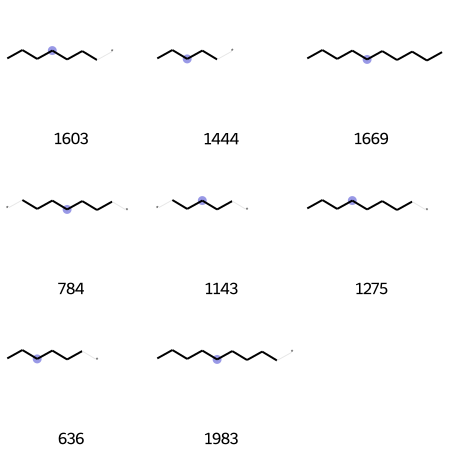

In [11]:
#picking bit information when radius is 7
#converting to lists since we cannot index from sets
uncommon_sub_decane = list(uncommon_bits_decane[7])
print('The unique substructures in decane is:\n')

decane_sub_images = [(decane_mol,x,bi_decane) for x in uncommon_sub_decane]
Draw.DrawMorganBits(decane_sub_images, legends=[str(x) for x in uncommon_sub_decane])

The unique substructure in pentane is:



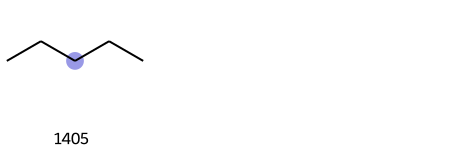

In [12]:
uncommon_sub_pentane = list(uncommon_bits_pentane[7])
pentane_sub_images = [(pentane_mol,x,bi_pentane) for x in uncommon_sub_pentane]
print('The unique substructure in pentane is:\n')
Draw.DrawMorganBits(pentane_sub_images, legends=[str(x) for x in uncommon_sub_pentane])

The common substructures to both:



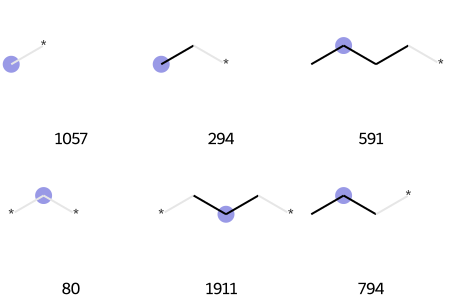

In [13]:
common_sub = list(commonBits[1])
common_sub_images = [(pentane_mol,x,bi_pentane) for x in common_sub]
print('The common substructures to both:\n')
Draw.DrawMorganBits(common_sub_images, legends=[str(x) for x in common_sub])

**<font color=orange> Extra Credit Problem: </font>** Find the canonical SMILES strings for all (or many) of the molecules in the ThermoProperties dataset. I don't know how to do this! I bet there's an answer somewhere on the Internet, but I haven't worked it out, yet. If you solve this, I would be very happy, and will include this in next year's course.

How many molecules in the ThermoProperties dataset can you represent using SMILES?

In [14]:
import pandas as pd
ThermoProperties = pd.read_csv('ThermoProperties.csv')

In [ ]:
from urllib.request import urlopen
from urllib.parse import quote

#This collects isomeric SMILES
def name_to_smiles(name):
    try:
        url = 'http://cactus.nci.nih.gov/chemical/structure/' + quote(name) + '/smiles'
        ans = urlopen(url).read().decode('utf8', 'U+00B1')
        return ans
    except:
        return 'Did not work'


identifiers  = ThermoProperties['name']

SMILES = []
for ids in identifiers:
    SMILES.append(name_to_smiles(ids))
    
print(SMILES)

In [ ]:
pd.set_option('display.max_rows', None)
ThermoProperties['SMILES (Isomeric)'] = SMILES
ThermoProperties

In [ ]:
import pubchempy

#This collects canonical SMILES 
def pubchem(names):
        try:
            PubChem_CID = pubchempy.get_compounds(names, namespace='name')
            match = PubChem_CID[0]
            ans = match.canonical_smiles
            return ans
        except:
            return 'Did not work'


Thermonames = [x for x in ThermoProperties['name']]

SMILES_PubChem = []
for n in Thermonames:
    SMILES_PubChem.append(pubchem(n))
    
print(SMILES_PubChem)

In [ ]:
ThermoProperties['SMILES (Canonical)'] = SMILES_PubChem
ThermoProperties

In [21]:
#Cis and trans are not recognized separately from both websites
#Some names have additional information e.g. "isomers", need to remove those for proper recognition
#Symols like (<+->), -a-,-b-, (±) are not also recognized, replacing -a- with -alpha- works
#Overall some name formatting could improve results

ThermoProperties.to_csv("ThermoPropertiesSMILES.csv", encoding='utf-8', index=False)